This page explores the finished analysis dataset: one row per drug per year on the market,
2020 to 2025, with the outcome (did a new shortage start that year?) and the predictor columns.
How that dataset was built and checked is on the
[Pipeline and Quality Checks](data-pipeline.ipynb) page.

It is organized by research question. Each figure states what it asks, then what we learned.
Everything here is description, not a model: a difference shown here doesn't control for any
other factor, and with about 160 shortage onsets, small differences can be noise. Confidence
intervals are shown wherever a comparison is made.

To reproduce it, run the pipeline in the repository README, then re-run this notebook from the
`site/` folder.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator, PercentFormatter

REPO_ROOT = Path.cwd().parent
assert (REPO_ROOT / "pyproject.toml").exists(), "run this notebook from the site/ folder"
INTERIM_DATA_DIR = REPO_ROOT / "data" / "interim"
PROCESSED_DATA_DIR = REPO_ROOT / "data" / "processed"

sys.path.insert(0, str(REPO_ROOT / "src" / "panel"))
import add_features as feature_building  # noqa: E402

features = pd.read_parquet(PROCESSED_DATA_DIR / "unit_year_features.parquet")
spells = pd.read_parquet(INTERIM_DATA_DIR / "shortage_spells.parquet")
units = pd.read_parquet(INTERIM_DATA_DIR / "units.parquet")
episodes = pd.read_parquet(INTERIM_DATA_DIR / "shortage_episodes_clean.parquet")

LABEL_YEARS = range(2020, 2026)
at_risk = features[features["at_risk"]]
BASE_RATE = at_risk["onset"].mean()
known_start_spells = spells[~spells["start_unknown"]].merge(units, on="unit_id")
# The spells that are onsets in the panel: known start, in a label year, and for a drug that had a
# package on the market at the end of the year before.
onset_spells = known_start_spells.assign(year=known_start_spells["start"].dt.year).merge(
    features.loc[features["onset"] == 1, ["unit_id", "year"]], on=["unit_id", "year"]
)
rng = np.random.default_rng(5502)

NUMERIC_FEATURES = [
    "active_packages",
    "active_applications",
    "active_generic_applications",
    "active_labelers",
    "package_exits_prior_year",
    "application_exits_prior_year",
    "discontinuation_notices_prior_year",
    "years_since_first_approval",
    "cumulative_applicants",
    "had_prior_shortage",
    "recalls_prior_year",
    "serious_recalls_prior_year",
]

In [2]:
SURFACE, TEXT_PRIMARY, TEXT_SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.size": 10,
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlecolor": TEXT_PRIMARY,
        "axes.titlepad": 12,
        "axes.labelcolor": TEXT_SECONDARY,
        "xtick.color": TEXT_SECONDARY,
        "ytick.color": TEXT_SECONDARY,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.edgecolor": BASELINE,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "legend.frameon": False,
        "lines.linewidth": 2,
    }
)


def wilson_interval(successes, trials, z=1.96):
    """95% confidence interval for a proportion; stays sensible when counts are small."""
    successes, trials = np.asarray(successes, float), np.asarray(trials, float)
    rate = successes / trials
    denominator = 1 + z**2 / trials
    center = (rate + z**2 / (2 * trials)) / denominator
    half_width = z * np.sqrt(rate * (1 - rate) / trials + z**2 / (4 * trials**2)) / denominator
    return np.clip(center - half_width, 0, None), center + half_width

## The outcome over time

**When do drugs go into shortage?** Each bar counts the drugs (ingredient + route) that went into
a new shortage that month. The right panel compares our yearly totals with the new drug shortages
FDA reports to Congress for its drug center (CDER), which, like our data, excludes biologics.
FDA's reports: [CY2023](https://www.fda.gov/media/179156/download),
[CY2024](https://www.fda.gov/media/189325/download),
[CY2025](https://www.fda.gov/media/193637/download) (Appendix C of each).

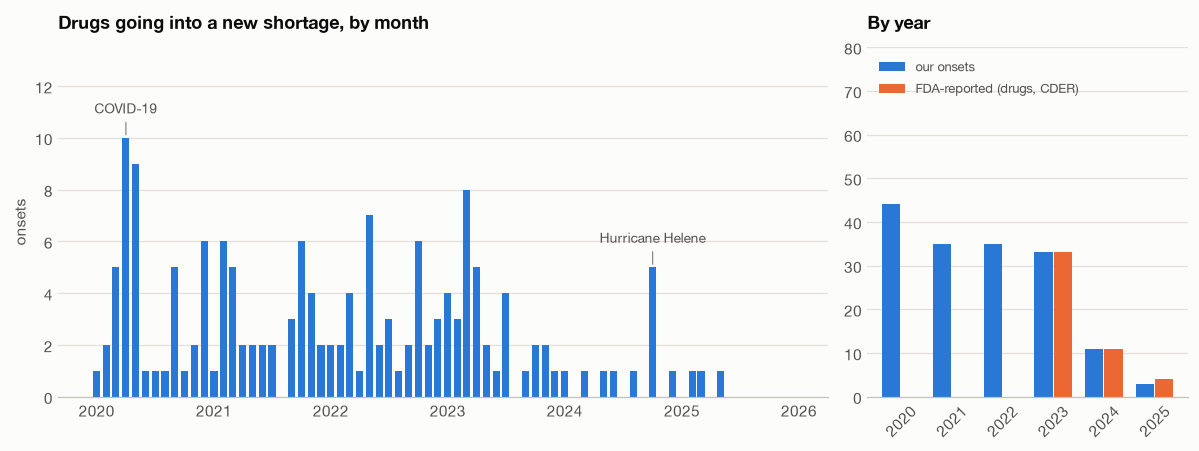

In [3]:
#| label: fig-onsets
#| fig-cap: "Shortage onsets by month, and by year compared with FDA's own counts"
onset_month = onset_spells["start"].dt.to_period("M")
months = pd.period_range("2020-01", "2025-12", freq="M")
onsets_by_month = onset_month.value_counts().reindex(months, fill_value=0)

fig, (ax_month, ax_year) = plt.subplots(1, 2, figsize=(11, 4.2), width_ratios=[3, 1.25])
ax_month.bar(months.to_timestamp(), onsets_by_month.to_numpy(), width=22, color=BLUE)
ax_month.set_title("Drugs going into a new shortage, by month")
ax_month.set_ylabel("onsets")
for label, month in [("COVID-19", "2020-04"), ("Hurricane Helene", "2024-10")]:
    ax_month.annotate(
        label,
        xy=(pd.Period(month).to_timestamp(), onsets_by_month[pd.Period(month)]),
        xytext=(0, 16),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color=TEXT_SECONDARY,
        arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8},
    )
ax_month.set_ylim(0, onsets_by_month.max() * 1.35)

# CDER-only new shortages, from Appendix C of FDA's CY2023-CY2025 Reports to Congress.
# The headline totals (55, 15, 4) also count biologics (CBER), which our data excludes.
FDA_REPORTED_NEW_SHORTAGES = {2023: 33, 2024: 11, 2025: 4}
onsets_by_year = onset_spells["year"].value_counts().reindex(LABEL_YEARS)
positions = np.arange(len(LABEL_YEARS))
ax_year.bar(positions - 0.19, onsets_by_year.to_numpy(), width=0.36, color=BLUE, label="our onsets")
fda_positions = [
    positions[list(LABEL_YEARS).index(year)] + 0.19 for year in FDA_REPORTED_NEW_SHORTAGES
]
ax_year.bar(
    fda_positions,
    list(FDA_REPORTED_NEW_SHORTAGES.values()),
    width=0.36,
    color=ORANGE,
    label="FDA-reported (drugs, CDER)",
)
ax_year.set_xticks(positions, [str(year) for year in LABEL_YEARS], rotation=45)
ax_year.set_title("By year")
ax_year.set_ylim(0, 80)
ax_year.legend(loc="upper left", fontsize=8.5, labelcolor=TEXT_SECONDARY)
fig.tight_layout()
plt.show()

In [4]:
pd.DataFrame(
    {
        "our onsets": onsets_by_year,
        "FDA-reported new drug shortages (CDER)": pd.Series(FDA_REPORTED_NEW_SHORTAGES),
    }
).rename_axis("year").T.fillna("").astype(str).replace(r"\.0$", "", regex=True)

year,2020,2021,2022,2023,2024,2025
our onsets,44,35,35,33,11,3
FDA-reported new drug shortages (CDER),,,,33,11,4


**What we learned.** From 2020 to 2023, between 33 and 44 drugs a year went into a new
shortage, a few in a typical month. The largest spike is April and May 2020, the start of the
COVID-19 pandemic. After 2023, onsets nearly stop: 11 in 2024 and 3 in 2025. The one 2024 bump,
in October, is mostly dialysis and IV solutions, which coincides with Hurricane Helene's damage
to Baxter's IV-fluid plant in North Carolina.

FDA's own counts of new drug shortages track ours closely (33, 11 and 4 against our 33, 11 and 3),
including the collapse after 2023. That agreement is the strongest check we have that the
reconstruction captures what FDA itself counts. For modeling, 2024 and 2025 hold too few onsets
to serve as test years on their own.

## Which drugs go into shortage (research question 2)

### The features at a glance

Summary statistics for the rows a model would learn from: drug-years at risk of a new shortage.
Most features are counts that are zero for most drugs and large for a few, so the median and the
share of zeros say more than the mean. Skewness measures how lopsided a distribution is: 0 is
symmetric, and large positive values mean a long tail of a few very large counts.

In [5]:
numeric = at_risk[NUMERIC_FEATURES].astype(float)
pd.DataFrame(
    {
        "mean": numeric.mean(),
        "median": numeric.median(),
        "90th percentile": numeric.quantile(0.9),
        "max": numeric.max(),
        "share zero": (numeric == 0).mean().map("{:.0%}".format),
        "skewness": numeric.skew(),
    }
).round(2).rename_axis("feature (at-risk rows)")

,mean,median,90th percentile,max,share zero,skewness
feature (at-risk rows),,,,,,
active_packages,52.88,9.0,124.0,1824.0,0%,4.99
active_applications,5.05,2.0,13.0,75.0,0%,3.17
active_generic_applications,3.87,1.0,11.0,68.0,42%,3.07
active_labelers,8.85,3.0,25.0,108.0,0%,2.47
package_exits_prior_year,7.08,0.0,15.0,636.0,57%,7.99
application_exits_prior_year,0.22,0.0,1.0,25.0,85%,7.91
discontinuation_notices_prior_year,0.12,0.0,0.0,23.0,96%,10.63
years_since_first_approval,23.63,24.3,41.0,43.0,0%,-0.14
cumulative_applicants,7.31,4.0,19.0,73.0,0%,2.24


**What we learned.** Most features are heavily lopsided: a typical drug has 9 packages on
the market, but a few have hundreds or thousands, and recalls and exits are zero for most
drug-years. A linear model would be dominated by the few extreme drugs, so the modeling step will
likely need to log-transform these counts. Every drug in the panel has at least one package
on the market, by construction. Years since first approval looks evenly spread, but a
quarter of its values are not real ages. The Orange Book doesn't date approvals before 1982, so
those drugs carry a capped, lower-bound age. The market-structure figure below gives them their
own group. Only 5% of at-risk drug-years had a prior shortage, partly because the archive's
history only begins in late 2019.

### Route of administration

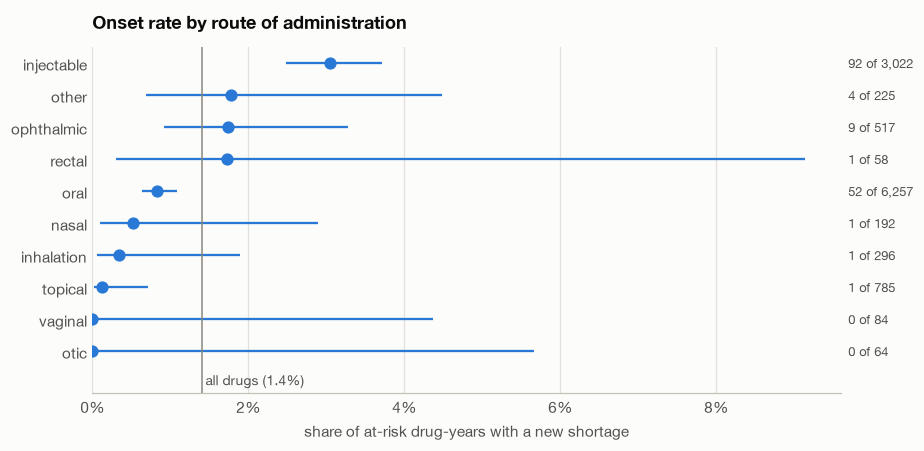

In [6]:
#| label: fig-route
#| fig-cap: "Yearly shortage onset rate by route group, with 95% confidence intervals"
by_route = at_risk.groupby("route_group")["onset"].agg(onsets="sum", drug_years="size")
by_route["rate"] = by_route["onsets"] / by_route["drug_years"]
by_route["low"], by_route["high"] = wilson_interval(by_route["onsets"], by_route["drug_years"])
by_route = by_route.sort_values("rate")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(by_route))
ax.errorbar(
    by_route["rate"],
    y,
    xerr=[by_route["rate"] - by_route["low"], by_route["high"] - by_route["rate"]],
    fmt="o",
    color=BLUE,
    ecolor=BLUE,
    elinewidth=1.5,
    markersize=7,
    capsize=0,
)
ax.axvline(BASE_RATE, color=MUTED, linewidth=1)
ax.text(
    BASE_RATE, -0.9, f" all drugs ({BASE_RATE:.1%})", color=TEXT_SECONDARY, fontsize=9, va="center"
)
ax.set_ylim(-1.3, len(by_route) - 0.5)
ax.set_yticks(y, by_route.index)
for position, (onsets, drug_years) in enumerate(zip(by_route["onsets"], by_route["drug_years"])):
    ax.text(
        1.01,
        position,
        f"{onsets} of {drug_years:,}",
        transform=ax.get_yaxis_transform(),
        va="center",
        fontsize=8.5,
        color=TEXT_SECONDARY,
    )
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, None)
ax.set_xlabel("share of at-risk drug-years with a new shortage")
ax.set_title("Onset rate by route of administration")
fig.tight_layout()
plt.show()

In [7]:
(
    by_route.sort_values("rate", ascending=False)
    .assign(
        rate=lambda table: table["rate"].map("{:.1%}".format),
        interval=lambda table: [
            f"{low:.1%} to {high:.1%}" for low, high in zip(table["low"], table["high"])
        ],
    )[["drug_years", "onsets", "rate", "interval"]]
    .rename(
        columns={
            "drug_years": "at-risk drug-years",
            "rate": "onset rate",
            "interval": "95% interval",
        }
    )
    .rename_axis("route group")
)

,at-risk drug-years,onsets,onset rate,95% interval
route group,,,,
injectable,3022,92,3.0%,2.5% to 3.7%
other,225,4,1.8%,0.7% to 4.5%
ophthalmic,517,9,1.7%,0.9% to 3.3%
rectal,58,1,1.7%,0.3% to 9.1%
oral,6257,52,0.8%,0.6% to 1.1%
nasal,192,1,0.5%,0.1% to 2.9%
inhalation,296,1,0.3%,0.1% to 1.9%
topical,785,1,0.1%,0.0% to 0.7%
otic,64,0,0.0%,0.0% to 5.7%


**What we learned.** Injectable drugs go into shortage at nearly four times the rate of oral
drugs (3.0% vs 0.8% of at-risk drug-years), and their intervals don't come close to overlapping.
Topical drugs are also clearly lower than injectables. This fits what is known about US
shortages: sterile injectables are hard and expensive to make and often have few suppliers
[@gao2016factors]. Most of the smaller groups have intervals too wide to say much. Rectal, for
example, rests on 1 onset in 58 drug-years, so a model will probably need to pool them.

### Market structure

**Is a drug with few manufacturers riskier? Is an old, heavily genericized one?** Each panel
groups at-risk drug-years by one market feature and shows the onset rate in each group. The gray
line is the rate across all drugs.

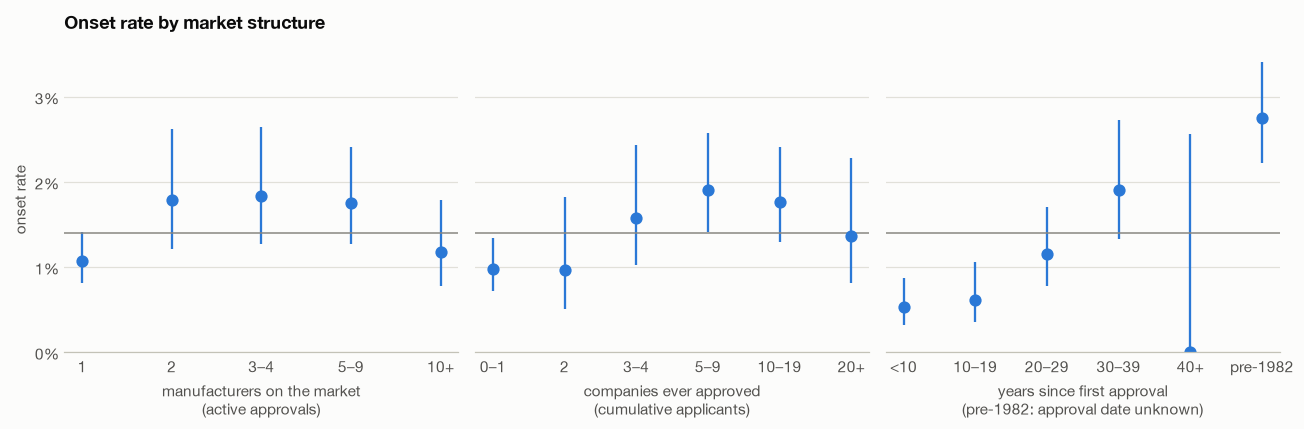

In [8]:
#| label: fig-market-structure
#| fig-cap: "Onset rate by number of manufacturers, cumulative applicants, and drug age"
MARKET_BINS = {
    "active_applications": (
        "manufacturers on the market\n(active approvals)",
        [1, 2, 3, 5, 10, np.inf],
        ["1", "2", "3–4", "5–9", "10+"],
    ),
    "cumulative_applicants": (
        "companies ever approved\n(cumulative applicants)",
        [0, 2, 3, 5, 10, 20, np.inf],
        ["0–1", "2", "3–4", "5–9", "10–19", "20+"],
    ),
    "years_since_first_approval": (
        "years since first approval\n(pre-1982: approval date unknown)",
        [0, 10, 20, 30, 40, np.inf],
        ["<10", "10–19", "20–29", "30–39", "40+"],
    ),
}

# The Orange Book dates approvals before 1982 only as "Approved Prior to Jan 1, 1982", so those
# drugs' ages are unknown. The feature caps them at 1982, which would put them all in one age bin
# that shifts with the calendar year; here they get their own group instead.
application_units = pd.read_parquet(INTERIM_DATA_DIR / "application_units.parquet")
first_approval = (
    feature_building.load_unit_approvals(application_units).groupby("unit_id")["approved"].min()
)
undated_units = set(first_approval.index[first_approval == feature_building.PRE_1982_APPROVAL])
is_undated = at_risk["unit_id"].isin(undated_units)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
market_tables = {}
for ax, (column, (label, edges, names)) in zip(axes, MARKET_BINS.items()):
    group = pd.cut(at_risk[column], edges, labels=names, right=False)
    if column == "years_since_first_approval":
        group = group.cat.add_categories("pre-1982").where(~is_undated, "pre-1982")
    table = at_risk.groupby(group, observed=False)["onset"].agg(onsets="sum", drug_years="size")
    table["rate"] = table["onsets"] / table["drug_years"]
    table["low"], table["high"] = wilson_interval(table["onsets"], table["drug_years"])
    market_tables[label.replace("\n", " ")] = table
    x = np.arange(len(table))
    ax.errorbar(
        x,
        table["rate"],
        yerr=[table["rate"] - table["low"], table["high"] - table["rate"]],
        fmt="o",
        color=BLUE,
        ecolor=BLUE,
        elinewidth=1.5,
        markersize=7,
        capsize=0,
    )
    ax.axhline(BASE_RATE, color=MUTED, linewidth=1)
    ax.set_xticks(x, table.index)
    ax.set_xlabel(label)
axes[0].yaxis.set_major_locator(MultipleLocator(0.01))
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylim(0, None)
axes[0].set_ylabel("onset rate")
axes[0].set_title("Onset rate by market structure")
fig.tight_layout()
plt.show()

In [9]:
pd.concat(
    {
        name: table.assign(rate=table["rate"].map("{:.1%}".format))[
            ["drug_years", "onsets", "rate"]
        ]
        for name, table in market_tables.items()
    }
).rename(columns={"drug_years": "at-risk drug-years", "rate": "onset rate"})

at-risk drug-years  \
manufacturers on the market (active approvals)     1                       4660   
                                                   2                       1400   
                                                   3–4                     1524   
                                                   5–9                     2057   
                                                   10+                     1859   
companies ever approved (cumulative applicants)    0–1                     3979   
                                                   2                        935   
                                                   3–4                     1263   
                                                   5–9                     2152   
                                                   10–19                   2150   
                                                   20+                     1021   
years since first approval (pre-1982: approval ... <10                     2847   
                                                   10–19                   1962   
                                                   20–29                   2086   
                                                   30–39                   1521   
                                                   40+                      146   
                                                   pre-1982                2938   

                                                             onsets onset rate  
manufacturers on the market (active approvals)     1             50       1.1%  
                                                   2             25       1.8%  
                                                   3–4           28       1.8%  
                                                   5–9           36       1.8%  
                                                   10+           22       1.2%  
companies ever approved (cumulative applicants)    0–1           39       1.0%  
                                                   2              9       1.0%  
                                                   3–4           20       1.6%  
                                                   5–9           41       1.9%  
                                                   10–19         38       1.8%  
                                                   20+           14       1.4%  
years since first approval (pre-1982: approval ... <10           15       0.5%  
                                                   10–19         12       0.6%  
                                                   20–29         24       1.2%  
                                                   30–39         29       1.9%  
                                                   40+            0       0.0%  
                                                   pre-1982      81       2.8%

**What we learned.**

- **Having few manufacturers is not, on its own, a warning sign here.** Drugs with one
  manufacturer go short *less* often (1.1%) than drugs with two to nine (about 1.8%). The dip
  at ten or more (1.2%) is within the noise. One limit: a "manufacturer" here is an FDA approval
  with packages sold in the US. The plants making the active ingredient, often abroad, are
  invisible in this data.
- **Companies ever approved** rises from under 1% to about 1.9% at 5 to 9 companies, then
  flattens.
- **Drug age shows the clearest pattern.** Risk rises steadily with age: 0.5% to 0.6% for drugs
  first approved less than 20 years ago, 1.2% at 20 to 29 years and 1.9% at 30 to 39. **Drugs
  approved before 1982**, whose exact age the Orange Book doesn't record, have the highest rate
  (2.8%) and account for 81 of the 161 onsets. Few drugs with a recorded approval are 40 or older,
  so that group is too small to read. Old, long-generic drugs make up much of the shortage
  problem, consistent with the low-margin explanation FDA gives [@fda2019roots].

These features are related (older drugs have accumulated more approvals), so these panels can't
separate their effects. That is a job for the model.

### All features compared

**How different are drugs that went into shortage, feature by feature?** Each dot is the ratio of
a feature's average in drug-years with an onset to its average in drug-years without one. A ratio
of 2 means the feature is twice as large, on average, before a shortage. The bars are 95%
intervals from resampling the data 2,000 times; a bar that crosses 1 means no clear
difference.

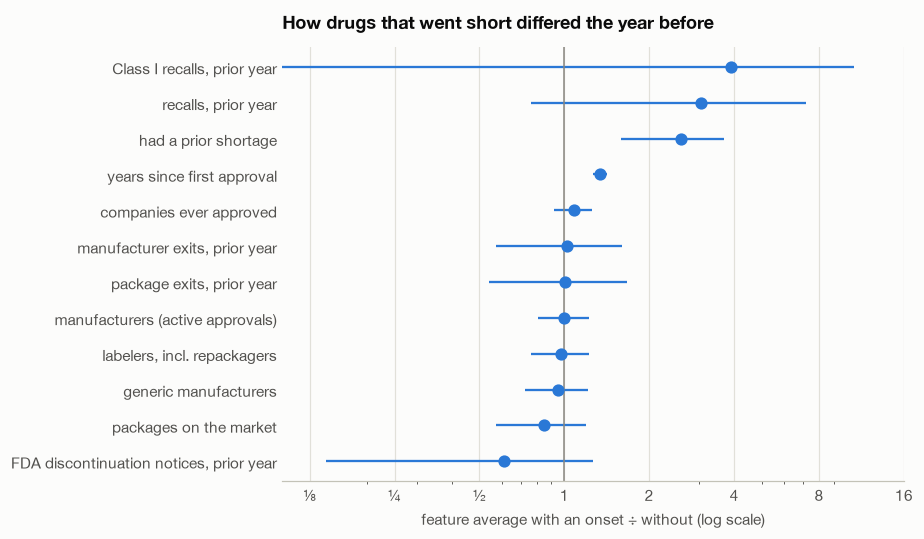

In [10]:
#| label: fig-feature-ratios
#| fig-cap: "Ratio of feature averages, onset vs no onset, with 95% bootstrap intervals"
with_onset = at_risk.loc[at_risk["onset"] == 1, NUMERIC_FEATURES].astype(float).to_numpy()
without_onset = at_risk.loc[at_risk["onset"] == 0, NUMERIC_FEATURES].astype(float).to_numpy()

RESAMPLES = 2000
resampled_ratios = np.empty((RESAMPLES, len(NUMERIC_FEATURES)))
for draw in range(RESAMPLES):
    onset_sample = with_onset[rng.integers(0, len(with_onset), len(with_onset))]
    other_sample = without_onset[rng.integers(0, len(without_onset), len(without_onset))]
    resampled_ratios[draw] = onset_sample.mean(axis=0) / other_sample.mean(axis=0)

ratios = pd.DataFrame(
    {
        "no onset": without_onset.mean(axis=0),
        "onset": with_onset.mean(axis=0),
        "ratio": with_onset.mean(axis=0) / without_onset.mean(axis=0),
        "low": np.nanpercentile(resampled_ratios, 2.5, axis=0),
        "high": np.nanpercentile(resampled_ratios, 97.5, axis=0),
    },
    index=NUMERIC_FEATURES,
).sort_values("ratio")

FEATURE_LABELS = {
    "active_packages": "packages on the market",
    "active_applications": "manufacturers (active approvals)",
    "active_generic_applications": "generic manufacturers",
    "active_labelers": "labelers, incl. repackagers",
    "package_exits_prior_year": "package exits, prior year",
    "application_exits_prior_year": "manufacturer exits, prior year",
    "discontinuation_notices_prior_year": "FDA discontinuation notices, prior year",
    "years_since_first_approval": "years since first approval",
    "cumulative_applicants": "companies ever approved",
    "had_prior_shortage": "had a prior shortage",
    "recalls_prior_year": "recalls, prior year",
    "serious_recalls_prior_year": "Class I recalls, prior year",
}

fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(ratios))
ax.errorbar(
    ratios["ratio"],
    y,
    xerr=[ratios["ratio"] - ratios["low"], ratios["high"] - ratios["ratio"]],
    fmt="o",
    color=BLUE,
    ecolor=BLUE,
    elinewidth=1.5,
    markersize=7,
    capsize=0,
)
ax.axvline(1, color=MUTED, linewidth=1)
ax.set_xscale("log")
ax.set_xlim(0.1, 16)
ax.set_xticks([0.125, 0.25, 0.5, 1, 2, 4, 8, 16], ["⅛", "¼", "½", "1", "2", "4", "8", "16"])
ax.set_yticks(y, [FEATURE_LABELS[feature] for feature in ratios.index])
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("feature average with an onset ÷ without (log scale)")
ax.set_title("How drugs that went short differed the year before")
fig.tight_layout()
plt.show()

In [11]:
ratios[["no onset", "onset", "ratio", "low", "high"]].iloc[::-1].round(2).rename(
    columns={"low": "95% low", "high": "95% high"}
).rename_axis("feature (mean, at-risk rows)")

,no onset,onset,ratio,95% low,95% high
"feature (mean, at-risk rows)",,,,,
serious_recalls_prior_year,0.01,0.03,3.91,0.00,10.61
recalls_prior_year,0.17,0.52,3.05,0.76,7.17
had_prior_shortage,0.05,0.14,2.60,1.59,3.69
years_since_first_approval,23.51,31.44,1.34,1.26,1.41
cumulative_applicants,7.30,7.88,1.08,0.92,1.25
application_exits_prior_year,0.22,0.23,1.02,0.57,1.59
package_exits_prior_year,7.08,7.14,1.01,0.54,1.67
active_applications,5.05,5.02,0.99,0.80,1.23
active_labelers,8.86,8.64,0.98,0.76,1.22


**What we learned.** Only two features clearly differ the year before a shortage:

- **A prior shortage**: drug-years with an onset were about 2.5 times as likely to have had an
  earlier shortage (interval 1.6 to 3.7). Shortage history was also among the most informative
  variables in the prediction studies by Roe et al. [@roe2026korea] and Pall et al.
  [@pall2023predicting].
- **Drug age**: drugs that went short were about a third older on average (interval 1.26 to
  1.41). The ages of pre-1982 drugs are lower bounds, so the true gap is probably larger.

Recalls *look* large (3 to 4 times as many on average), but their intervals cross 1. The average
is driven by a few drugs with many recalls, so we can't be confident the difference is real. For
supply structure, exits and FDA discontinuation notices, every interval spans 1: in the year
before a shortage, these drugs were not distinguishable from the rest.

The intervals treat each drug-year as independent, though each drug appears in up to six years.
Resampling whole drugs instead gives nearly identical intervals.

### Which features measure the same thing

With about 160 onsets, a model can only use a limited number of features, so features that carry
the same information are worth knowing before modeling. The table shows rank correlations
(Spearman) between features across at-risk drug-years: 1 means two features rise and fall
together perfectly, 0 means no relationship.

In [12]:
correlations = at_risk[NUMERIC_FEATURES].astype(float).corr(method="spearman")
strongly_related = [
    (first, second, correlations.loc[first, second])
    for position, first in enumerate(NUMERIC_FEATURES)
    for second in NUMERIC_FEATURES[position + 1 :]
    if abs(correlations.loc[first, second]) >= 0.7
]
print("feature pairs with |correlation| >= 0.7:")
for first, second, value in sorted(strongly_related, key=lambda pair: -abs(pair[2])):
    print(f"  {value:+.2f}  {first} / {second}")
correlations.round(2)

feature pairs with |correlation| >= 0.7:
  +0.94  active_applications / active_generic_applications
  +0.93  active_generic_applications / cumulative_applicants
  +0.92  active_applications / active_labelers
  +0.91  active_generic_applications / active_labelers
  +0.89  active_packages / active_labelers
  +0.88  active_applications / cumulative_applicants
  +0.88  active_labelers / cumulative_applicants
  +0.86  active_packages / active_applications
  +0.82  active_packages / active_generic_applications
  +0.79  active_packages / cumulative_applicants
  +0.72  active_labelers / package_exits_prior_year
  +0.70  active_packages / package_exits_prior_year


,active_packages,active_applications,active_generic_applications,active_labelers,package_exits_prior_year,application_exits_prior_year,discontinuation_notices_prior_year,years_since_first_approval,cumulative_applicants,had_prior_shortage,recalls_prior_year,serious_recalls_prior_year
active_packages,1.00,0.86,0.82,0.89,0.70,0.39,0.17,0.36,0.79,0.07,0.28,0.06
active_applications,0.86,1.00,0.94,0.92,0.67,0.42,0.20,0.46,0.88,0.09,0.30,0.07
active_generic_applications,0.82,0.94,1.00,0.91,0.68,0.44,0.19,0.52,0.93,0.09,0.29,0.07
active_labelers,0.89,0.92,0.91,1.00,0.72,0.42,0.18,0.48,0.88,0.09,0.29,0.06
package_exits_prior_year,0.70,0.67,0.68,0.72,1.00,0.54,0.17,0.34,0.67,0.04,0.25,0.05
application_exits_prior_year,0.39,0.42,0.44,0.42,0.54,1.00,0.15,0.21,0.46,0.00,0.15,0.03
discontinuation_notices_prior_year,0.17,0.20,0.19,0.18,0.17,0.15,1.00,0.09,0.19,0.01,0.06,0.02
years_since_first_approval,0.36,0.46,0.52,0.48,0.34,0.21,0.09,1.00,0.60,0.18,0.12,0.04
cumulative_applicants,0.79,0.88,0.93,0.88,0.67,0.46,0.19,0.60,1.00,0.11,0.27,0.06
had_prior_shortage,0.07,0.09,0.09,0.09,0.04,0.00,0.01,0.18,0.11,1.00,0.01,0.00


**What we learned.** The five supply-structure counts are strongly correlated (0.79 to 0.94):
packages, manufacturers, generic manufacturers, labelers, and companies ever approved. They
mostly measure one thing, the size of a drug's market, so a model should use one or two of them,
not all five. Package exits are also fairly strongly correlated with market size (about 0.67 to 0.72),
since a drug with more packages has more that can be discontinued. That suggests expressing exits
relative to market size, for example as a share of packages, rather than as a raw count. Prior
shortage, recalls and discontinuation notices are only weakly related to the rest, so they carry
separate information.

## What the data offers for studying exits (research question 3)

Research question 3 asks whether manufacturers leave a market before a shortage is declared.
Answering it needs an event study: following each drug's packages through the months around its
shortage onset and comparing them with similar drugs. That analysis belongs to the next
milestone. This section describes the data such a study would work with, and the design choices
that data forces.

### Packages on the market, and how they change

The left panel follows all drugs together: the number of packages on the market each month and
the number of drugs with at least one, both indexed to 100 in January 2019. The right panel shows
how much a single drug's package count typically changes in a year, across all drug-years in the
panel.

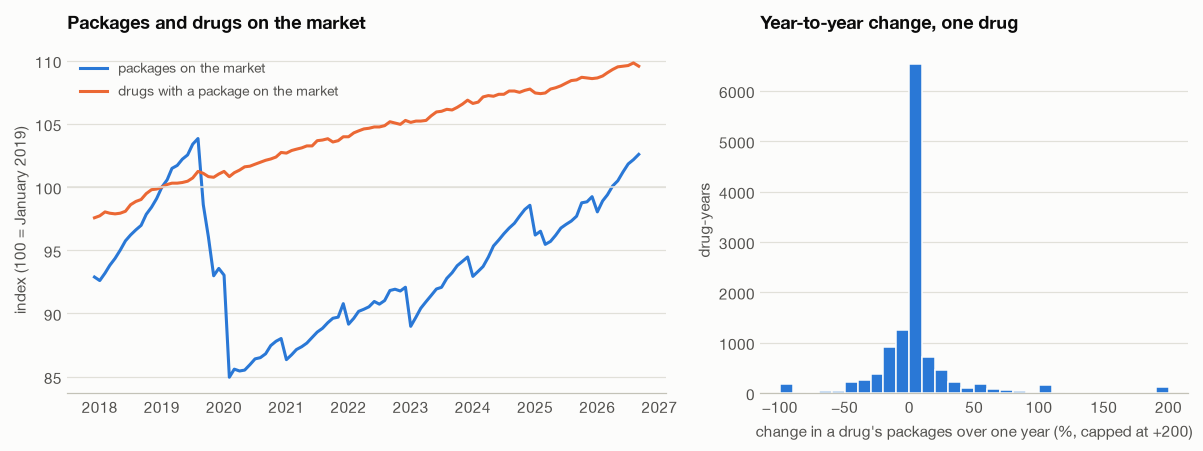

In [13]:
#| label: fig-package-data
#| fig-cap: "Packages on the market over time, and yearly change in one drug's package count"
packages = feature_building.load_unit_packages(application_units)

FIRST_MONTH, LAST_MONTH = pd.Period("2017-12", "M"), pd.Period("2026-09", "M")
month_count = (LAST_MONTH - FIRST_MONTH).n + 1


def month_index(dates: pd.Series) -> pd.Series:
    return (dates.dt.year * 12 + dates.dt.month) - (FIRST_MONTH.year * 12 + FIRST_MONTH.month)


# active[unit, month] = packages on the market at the end of that month. A package counts from
# the month it starts until the month its marketing ends (inclusive if it ends on the last day).
entered = month_index(packages["start"]).clip(lower=0)
ends_on_month_end = packages["end"] == packages["end"] + pd.offsets.MonthEnd(0)
left = (month_index(packages["end"]) + ends_on_month_end.astype(int)).fillna(month_count)
changes = np.zeros((units["unit_id"].max() + 1, month_count + 1))
# Packages that left before the grid starts, or never started, are never counted.
in_grid = (entered < month_count) & (left > entered)
np.add.at(changes, (packages.loc[in_grid, "unit_id"], entered[in_grid].astype(int)), 1)
np.add.at(
    changes,
    (packages.loc[in_grid, "unit_id"], left[in_grid].clip(upper=month_count).astype(int)),
    -1,
)
active = changes.cumsum(axis=1)[:, :month_count]
months = pd.period_range(FIRST_MONTH, LAST_MONTH, freq="M")
january_2019 = list(months).index(pd.Period("2019-01", "M"))
total_packages = active.sum(axis=0)
drugs_on_market = (active > 0).sum(axis=0)


def december_index(year: int) -> int:
    return list(months).index(pd.Period(f"{year}-12", "M"))


# Every drug with packages at the end of one year, followed to the end of the next, for the same
# year pairs the panel uses. Taken from the monthly counts rather than the panel, because a drug
# that loses its last package leaves the panel and its exit would be hidden.
year_pairs = [(year - 2, year - 1) for year in LABEL_YEARS]
earlier_counts, later_counts = [], []
for earlier_year, later_year in year_pairs:
    on_market = active[:, december_index(earlier_year)] > 0
    earlier_counts.append(active[on_market, december_index(earlier_year)])
    later_counts.append(active[on_market, december_index(later_year)])
packages_a_year_earlier = np.concatenate(earlier_counts)
packages_a_year_later = np.concatenate(later_counts)
yearly_change = pd.Series(
    100 * (packages_a_year_later - packages_a_year_earlier) / packages_a_year_earlier
)

fig, (ax_trend, ax_change) = plt.subplots(1, 2, figsize=(11, 4.2), width_ratios=[1.4, 1])
ax_trend.plot(
    months.to_timestamp(),
    100 * total_packages / total_packages[january_2019],
    color=BLUE,
    label="packages on the market",
)
ax_trend.plot(
    months.to_timestamp(),
    100 * drugs_on_market / drugs_on_market[january_2019],
    color=ORANGE,
    label="drugs with a package on the market",
)
ax_trend.axhline(100, color=GRID, linewidth=1)
ax_trend.set_ylabel("index (100 = January 2019)")
ax_trend.set_title("Packages and drugs on the market")
ax_trend.legend(loc="upper left", fontsize=9, labelcolor=TEXT_SECONDARY)

ax_change.hist(
    yearly_change.clip(-100, 200),
    bins=np.arange(-100, 210, 10),
    color=BLUE,
    edgecolor=SURFACE,
    linewidth=1,
)
ax_change.set_xlabel("change in a drug's packages over one year (%, capped at +200)")
ax_change.set_ylabel("drug-years")
ax_change.set_title("Year-to-year change, one drug")
fig.tight_layout()
plt.show()

In [14]:
PACKAGE_COUNT_BINS = [1, 2, 4, 10, 50, np.inf]
PACKAGE_COUNT_LABELS = ["1", "2–3", "4–9", "10–49", "50+"]
earlier = pd.Series(packages_a_year_earlier)
later = pd.Series(packages_a_year_later)
size_group = pd.cut(earlier, PACKAGE_COUNT_BINS, labels=PACKAGE_COUNT_LABELS, right=False)
pd.DataFrame(
    {
        "drug-years": size_group.value_counts().reindex(PACKAGE_COUNT_LABELS),
        "share with any change": (later != earlier).groupby(size_group, observed=False).mean(),
        "share losing at least one package": (later < earlier)
        .groupby(size_group, observed=False)
        .mean(),
        "median size of a change, when one happens (%)": yearly_change.abs()[later != earlier]
        .groupby(size_group[later != earlier], observed=False)
        .median(),
    }
).round(2).rename_axis("packages a year earlier")

,drug-years,share with any change,share losing at least one package,"median size of a change, when one happens (%)"
packages a year earlier,,,,
1,1298,0.14,0.06,100.00
2–3,2177,0.23,0.11,50.00
4–9,2497,0.42,0.22,28.57
10–49,3514,0.71,0.35,14.29
50+,2500,0.95,0.49,7.44


In [15]:
# What an event study would have to work with, for each panel onset: package history before it
# and the pool of comparison drugs (same route group, not in shortage within two years before or
# one year after the onset, with packages on the market a year before).
route_of_unit = units.set_index("unit_id")["route_group"]
readiness_rows = []
for onset in onset_spells.itertuples():
    onset_month = (onset.start.year * 12 + onset.start.month) - (
        FIRST_MONTH.year * 12 + FIRST_MONTH.month
    )
    window_start = onset.start - pd.DateOffset(months=24)
    window_end = onset.start + pd.DateOffset(months=12)
    in_shortage_nearby = set(
        spells.loc[(spells["start"] <= window_end) & (spells["end"] >= window_start), "unit_id"]
    )
    same_route = route_of_unit.index[route_of_unit == onset.route_group]
    readiness_rows.append(
        {
            "route group": onset.route_group,
            "packages a year before": active[onset.unit_id, onset_month - 12],
            "window inside the data": onset_month - 24 >= 0 and onset_month + 12 < len(months),
            "comparison drugs": sum(
                unit_id not in in_shortage_nearby and active[unit_id, onset_month - 12] > 0
                for unit_id in same_route
            ),
        }
    )
readiness_table = pd.DataFrame(readiness_rows)
print(
    f"onsets: {len(readiness_table)}; with packages on the market a year before: "
    f"{(readiness_table['packages a year before'] > 0).sum()}; with 1 to 3 packages a year before: "
    f"{readiness_table['packages a year before'].between(1, 3).sum()}; with a full 24-month "
    f"history and 12 months after inside the data: "
    f"{readiness_table['window inside the data'].sum()}"
)
readiness_table.groupby("route group").agg(
    onsets=("comparison drugs", "size"),
    fewest_comparison_drugs=("comparison drugs", "min"),
    median_comparison_drugs=("comparison drugs", "median"),
).sort_values("onsets", ascending=False)

onsets: 161; with packages on the market a year before: 160; with 1 to 3 packages a year before: 39; with a full 24-month history and 12 months after inside the data: 161


,onsets,fewest_comparison_drugs,median_comparison_drugs
route group,,,
injectable,92,418,436.5
oral,52,960,987.5
ophthalmic,9,76,76.0
other,4,34,35.0
inhalation,1,47,47.0
nasal,1,30,30.0
rectal,1,9,9.0
topical,1,134,134.0


**What we learned.** Four things an event study of exits has to account for:

- **The market grows, and drugs and packages move differently.** The number of drugs with a
  package on the market rises steadily, about 12% from 2018 to 2026. Packages don't: their count
  falls abruptly in late 2019 and early 2020 and dips at the start of most years. Any comparison of
  exits before an onset has to be made against other drugs over the *same calendar months*, so that
  shared movements cancel out.
- **Exit dates are often administrative.** Most packages that leave the market have no marketing
  end date in NSDE, only an inactivation date, and those cluster on a handful of days: 90% of
  them fall on ten dates, mostly at the end of January. That pattern is consistent with FDA's
  annual listing certification, under which listings not renewed by year-end are inactivated in
  a batch. Such a date records when FDA removed a stale listing, not when the product left the
  market, so month-level exit timing is unreliable. An event study should work at a coarser
  scale, or check its results using marketing end dates alone.
- **Small markets make percentages unstable.** Most drug-years see no change in packages at all.
  For a drug with one package, any change is a 100% change, and for two to three packages,
  typically 50%. 39 of the 161 onsets involve drugs with only one to three packages a year before.
  For those, counts or exits at the level of FDA approvals are more meaningful than a percentage
  index.
- **Comparison drugs are plentiful for the common routes but not the rare ones.** Every onset has
  two years of history before it and one year after inside the data, and all but one had packages
  on the market a year before. Injectable and oral onsets each have hundreds of possible comparison
  drugs, but a rectal onset has nine, so rare routes will need pooling or matching on more than
  route.

None of this answers whether exits precede shortages; it sets out what the event study in the next
milestone has to handle. One related caution from the feature comparison above: exits in the
prior year looked no different before an onset, but those exit counts carry the same
administrative timing.

## How long shortages last

**Once a drug goes short, how long until the shortage ends?** Some shortages are still running at
the end of our data, and a simple average would treat them as if they had ended that day. A
survival curve handles them properly: it shows the share of shortages still running after each
number of months, using every shortage for as long as we observed it. Shortages that began
before the archive started are left out, since their start is unknown. The curve uses every
shortage with a known start, including a few that began in late 2019 or in 2026, so it covers
171 shortages rather than the panel's 161 onsets.

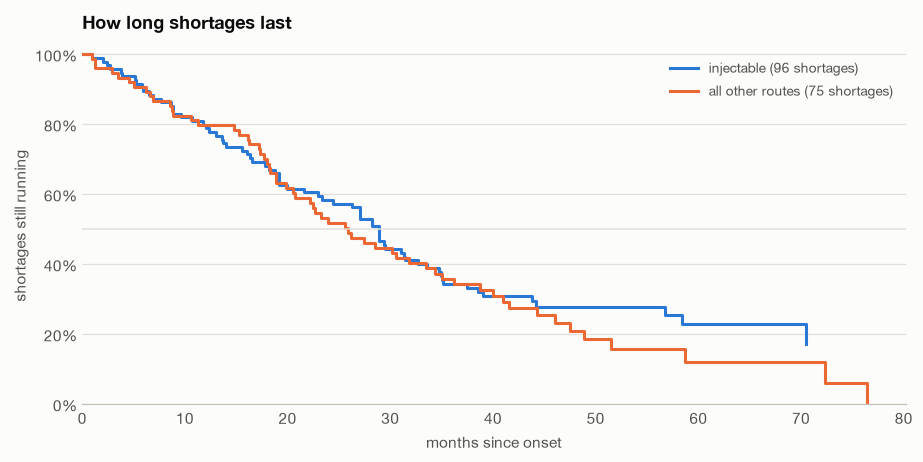

In [16]:
#| label: fig-duration
#| fig-cap: "Share of shortages still running, by months since onset"
def kaplan_meier(months_observed: pd.Series, ended: pd.Series) -> pd.Series:
    """Share still running after each observed ending time (the Kaplan-Meier estimate)."""
    times = np.sort(months_observed[ended].unique())
    still_running = []
    share = 1.0
    for time in times:
        at_risk_count = (months_observed >= time).sum()
        ended_count = ((months_observed == time) & ended).sum()
        share *= 1 - ended_count / at_risk_count
        still_running.append(share)
    return pd.Series([1.0, *still_running], index=[0.0, *times])


def median_duration(curve: pd.Series) -> float:
    below_half = curve[curve <= 0.5]
    return below_half.index[0] if len(below_half) else np.nan


durations = known_start_spells.assign(
    months=(known_start_spells["end"] - known_start_spells["start"]).dt.days / 30.44,
    ended=~known_start_spells["still_active"],
    group=np.where(
        known_start_spells["route_group"] == "injectable", "injectable", "all other routes"
    ),
)

fig, ax = plt.subplots(figsize=(8.5, 4.3))
duration_rows = {}
for group, color in [("injectable", BLUE), ("all other routes", ORANGE)]:
    subset = durations[durations["group"] == group]
    curve = kaplan_meier(subset["months"], subset["ended"])
    ax.step(
        curve.index,
        curve.to_numpy(),
        where="post",
        color=color,
        label=f"{group} ({len(subset)} shortages)",
    )
    duration_rows[group] = {
        "shortages": len(subset),
        "still running": int((~subset["ended"]).sum()),
        "median months": median_duration(curve),
    }
ax.axhline(0.5, color=GRID, linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.02)
ax.set_xlim(0, None)
ax.set_xlabel("months since onset")
ax.set_ylabel("shortages still running")
ax.set_title("How long shortages last")
ax.legend(loc="upper right", fontsize=9, labelcolor=TEXT_SECONDARY)
fig.tight_layout()
plt.show()

In [17]:
everything = kaplan_meier(durations["months"], durations["ended"])
duration_rows["all shortages"] = {
    "shortages": len(durations),
    "still running": int((~durations["ended"]).sum()),
    "median months": median_duration(everything),
}
pd.DataFrame(duration_rows).T.astype({"shortages": int, "still running": int}).round(
    {"median months": 1}
).rename_axis("")

,shortages,still running,median months
,,,
injectable,96,27,28.9
all other routes,75,16,25.9
all shortages,171,43,27.4


**What we learned.** Half of all shortages last longer than about 27 months, roughly two and a
quarter years, and 43 of the 171 are still running at the end of our data. Injectable shortages
and the rest have similar medians (29 and 26 months), and the curves stay close for the first
three years. Beyond about four years, injectable shortages are somewhat more likely to persist,
though few shortages remain that long, so that tail is uncertain. Durations this long are
consistent with recent reports that US shortages now last years, not months [@gao2025coordination].

HHS's analysis of 2018–2023 found a much larger gap, with median durations of 4.6 years for
injectables against 1.6 for oral drugs [@aspe2025shortages]. That analysis counts package codes
rather than drugs and covers a different window, and our durations are capped at about seven
years by the archive, so the two aren't directly comparable. The difference is still worth
keeping in mind before treating route as irrelevant to duration.

Two limits apply. A shortage's end is FDA's resolution date, or the last capture listing it when
FDA never recorded one. A few of those last captures sit at the start of the 2023 archive gap, so
those shortages may have run somewhat longer. Moving their ends to the next capture lengthens the
median by about a month.

## Reported causes over time (research question 4)

**Do the causes FDA records change from year to year?** The left panel shows the mix of reported
causes, grouped into five categories, for drugs with shortage episodes first listed each year.
FDA lists each package separately, so each drug counts once per year, with every cause any of its
packages gave. A drug citing several causes counts in each, so the panel shows shares of cause
mentions. The right panel shows the share of those drugs with no usable cause at all; the left
panel describes only the rest. The numbers are in the table below the figure.

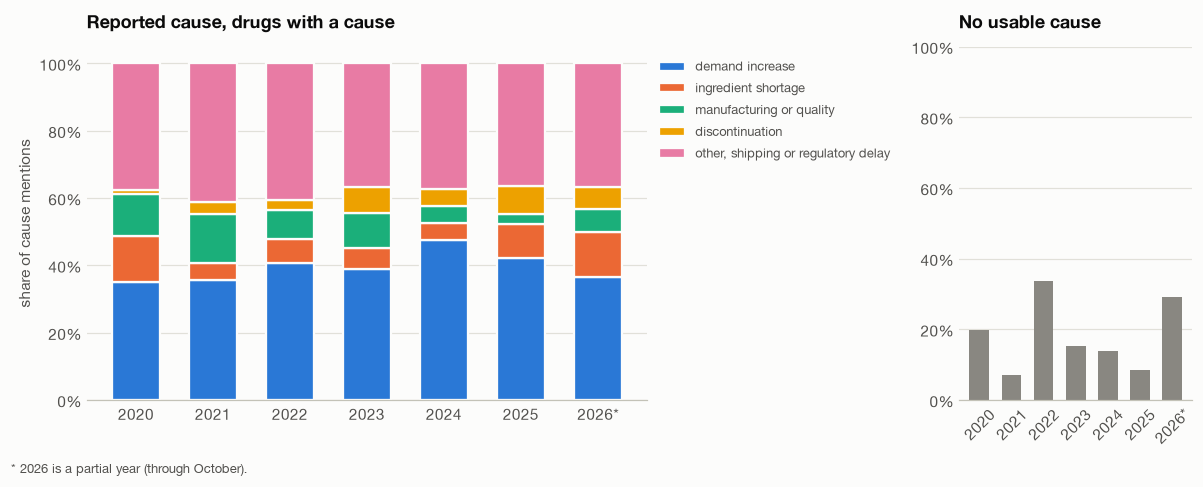

In [18]:
#| label: fig-causes
#| fig-cap: "Reported causes of shortage by year first listed, and share with no cause"
CAUSE_GROUPS = {
    "demand increase": ["demand_increase"],
    "ingredient shortage": ["active_ingredient", "inactive_ingredient"],
    "manufacturing or quality": ["gmp_compliance", "manufacturing_delay"],
    "discontinuation": ["discontinuation"],
    "other, shipping or regulatory delay": ["shipping_delay", "regulatory_delay", "other"],
}
CAUSE_COLORS = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
CAUSE_YEARS = range(2020, 2027)

# FDA lists each package separately, so one drug's shortage can produce dozens of episodes in a
# year. Counting each drug once per year keeps a few heavily listed drugs from dominating.
episode_units = pd.read_parquet(INTERIM_DATA_DIR / "episode_units.parquet")
shortage_episodes = episodes[episodes["statuses"] != "To Be Discontinued"]
reason_flags = [
    f"reason_{category}" for categories in CAUSE_GROUPS.values() for category in categories
]
linked = episode_units.join(
    shortage_episodes[["first_seen", "reason_missing", *reason_flags]], on="episode_id", how="inner"
)
linked["year"] = linked["first_seen"].dt.year
by_drug_year = linked.groupby(["unit_id", "year"])
cited = by_drug_year[reason_flags].max()
drug_year_mentions = pd.DataFrame(
    {
        group: cited[[f"reason_{category}" for category in categories]].any(axis=1)
        for group, categories in CAUSE_GROUPS.items()
    }
)
mentions = drug_year_mentions.groupby(level="year").sum().reindex(CAUSE_YEARS)
cause_shares = mentions.div(mentions.sum(axis=1), axis=0)
# A drug-year has no usable cause only if none of its episodes that year gave one.
no_cause = by_drug_year["reason_missing"].min().astype(bool)
missing_share = no_cause.groupby(level="year").mean().reindex(CAUSE_YEARS)
drug_years_listed = no_cause.groupby(level="year").size().reindex(CAUSE_YEARS)

fig, (ax_mix, ax_missing) = plt.subplots(1, 2, figsize=(11, 4.4), width_ratios=[2.4, 1])
year_labels = [str(year) if year < 2026 else "2026*" for year in CAUSE_YEARS]
bottom = np.zeros(len(CAUSE_YEARS))
for group, color in zip(CAUSE_GROUPS, CAUSE_COLORS):
    ax_mix.bar(
        year_labels,
        cause_shares[group],
        bottom=bottom,
        width=0.62,
        color=color,
        edgecolor=SURFACE,
        linewidth=1.5,
        label=group,
    )
    bottom += cause_shares[group].to_numpy()
ax_mix.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_mix.set_ylabel("share of cause mentions")
ax_mix.set_title("Reported cause, drugs with a cause")
ax_mix.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5, labelcolor=TEXT_SECONDARY)

ax_missing.bar(year_labels, missing_share.to_numpy(), width=0.62, color=MUTED)
ax_missing.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_missing.set_ylim(0, 1)
ax_missing.set_title("No usable cause")
ax_missing.tick_params(axis="x", labelrotation=45)
fig.text(
    0.01, 0.01, "* 2026 is a partial year (through October).", fontsize=8.5, color=TEXT_SECONDARY
)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [19]:
cause_table = cause_shares.map("{:.0%}".format)
cause_table["no usable cause"] = missing_share.map("{:.0%}".format)
cause_table["drugs with shortage episodes listed"] = drug_years_listed
cause_table.rename(index={2026: "2026 (partial)"}).rename_axis("year first listed")

,demand increase,ingredient shortage,manufacturing or quality,discontinuation,"other, shipping or regulatory delay",no usable cause,drugs with shortage episodes listed
year first listed,,,,,,,
2020,35%,14%,12%,1%,38%,20%,61
2021,36%,5%,15%,3%,41%,7%,100
2022,41%,7%,9%,3%,41%,34%,74
2023,39%,6%,10%,8%,37%,15%,145
2024,47%,5%,5%,5%,37%,14%,101
2025,42%,10%,3%,8%,36%,8%,72
2026 (partial),37%,13%,7%,7%,37%,29%,31


**What we learned.** The largest group every year is "other, shipping or regulatory delay"
(36% to 41% of mentions), and most of it is FDA's own catch-all "Other". So a large share of
causes is effectively unexplained even when one is reported. **Demand increase is the most
common specific cause**: 35% to 47% of mentions, and the most cited of the named causes in every
year. Manufacturing and quality problems account for 3% to 15%, highest in 2020 and 2021.

Counting each drug once per year matters here. Counted by package-level episodes instead, the
shares are skewed toward a few drugs with dozens of listed packages, and manufacturing problems
look rarer than they are.

Between 7% and 34% of drugs in a given full year have no usable cause for any of their packages.
That is lower than on the pipeline page, which counts package-level episodes, including
discontinuation notices, which rarely give a cause.

For research question 4, this matters directly. The question compares a period dominated by
quality problems with one dominated by demand. In our window, demand is the most cited specific
cause every year, and the years FDA described as dominated by quality problems, 2013 to 2017
[@fda2019roots], fall before the archive begins. So the question can't be tested as framed with
this data, and needs revising. The partial 2026 is too small (31 drugs) to read trends into.